# Phase 2 implementation checkpoint: explainable pediatric pneumonia classification

This checkpoint implements an image-input branch for future multiclass CNN experiments and a separate metadata diagnostic branch for acquisition/shortcut investigation. Metadata are not CNN predictors. No predictive model was trained and no clinical performance was estimated.

I retained canonical byte contents without claiming independent patients. Unresolved pHash relationships remain split constraints rather than confirmed duplicates or patient identities.

## 1. Reproducibility and paths

The notebook runs from the repository root or notebook directory using the project virtual environment and `requirements.txt`. Existing Phase 1 dependency pins are retained. Outer partitioning uses seed 42; internal validation uses seed 42 + outer-fold number and the first inner ten-fold partition. No search for favorable seeds or balance was performed.

PowerShell reproduction commands:
- `.\.venv\Scripts\python.exe -m unittest discover -s tests -v`
- `.\.venv\Scripts\python.exe -B phase2_implementation/execute_notebook.py`
- `.\.venv\Scripts\python.exe -m pip check`

The execution runner selects the active environment kernel explicitly and records cell coverage in `data/processed/phase2_notebook_execution.json`. The executed version table below identifies the actual environment; it does not imply equivalence to the Phase 1 interpreter.

In [1]:
from pathlib import Path
import os, sys, json
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/phase2_grouping.py').is_file()), None)
assert PROJECT is not None, 'I require the repository checkout.'
sys.path.insert(0, str(PROJECT))
os.environ['MPLCONFIGDIR'] = str(PROJECT / '.mplconfig')
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from src.phase2_diagnostics import run_checkpoint, raw_snapshot, snapshot_fingerprint, FIGURES
from src.phase2_grouping import load_manifest, constrain_groups, assert_partitions
from src.phase2_pipeline import load_canonical_image, pretrained_representation, resize_geometry, AugmentationConfig
from src.preprocessing_summary import read_table
summary = run_checkpoint(PROJECT)
OUT = PROJECT / 'data/processed'
display(pd.Series(summary['versions'], name='Executed version').to_frame())

I am fingerprinting every raw file before checkpoint execution.


I fitted fold 1 diagnostics on 4191 actual training rows.


I fitted fold 2 diagnostics on 4192 actual training rows.


I fitted fold 3 diagnostics on 4195 actual training rows.


I fitted fold 4 diagnostics on 4192 actual training rows.


I fitted fold 5 diagnostics on 4194 actual training rows.


I am verifying that every raw file and Phase 1 table is unchanged.


,Executed version
python,3.12.14
numpy,2.5.3
pandas,3.0.6
Pillow,12.3.0
matplotlib,3.11.2
scipy,1.18.1
scikit-learn,1.9.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


## 2. Canonical manifest verification

Verification covers unique hashes, recognized targets, path-derived labels, alternative-source label consistency, complete diagnostic predictors, and the Phase 1 manifest fingerprint. Every raw file is hashed before and after execution; image hashes are compared with the committed inventory. The canonical CSV is preserved.

In [2]:
canonical = load_manifest(PROJECT)
display(canonical.target_label.value_counts().rename('Canonical images').to_frame())
display(Markdown(f"I retained **{len(canonical):,} canonical contents**, with **{canonical.sha256_hash.nunique():,} unique SHA-256 values**. I verified {summary['raw_file_count']:,} raw files unchanged and retained manifest fingerprint `{summary['manifest_sha256']}`. This establishes reconstruction integrity; it does not establish patient independence."))

,Canonical images
target_label,
BACTERIAL_PNEUMONIA,2760
NORMAL,1579
VIRAL_PNEUMONIA,1485


I retained **5,824 canonical contents**, with **5,824 unique SHA-256 values**. I verified 17,591 raw files unchanged and retained manifest fingerprint `d23f6446949866a314efcc85809750bf9ddfe8d8f8108c75159795a05d0b6bd3`. This establishes reconstruction integrity; it does not establish patient independence.

## 3. Leakage-control grouping

Pneumonia `person<number>` tokens are grouped across subtype labels. Normal `IM` and `NORMAL2-IM` namespaces remain distinct, with each family grouped by its leading numeric token. The documented extra viral suffix is recognized as a relation signal without being promoted to a verified patient ID.

All unresolved pHash edges are retained as split-only constraints. Connected components combine these edges with the filename relations. Mixed-class components are permissible allocation constraints and must not be interpreted as patient identities.

In [3]:
candidates = read_table(OUT / 'near_duplicate_candidates.csv')
grouped = constrain_groups(canonical, candidates)
display(Markdown(f"I reproduced **{summary['base_relation_groups']:,} filename-derived base groups**. Retaining **{summary['unresolved_phash_edges']} unresolved candidate edges** produced **{summary['leakage_control_groups']:,} partition constraint components**; the largest contains {summary['largest_constraint_component_images']} images. I did not adjudicate these edges as duplicates or patients."))
display(grouped[['base_relation_group','leakage_control_group']].nunique().to_frame('Count'))

I reproduced **3,117 filename-derived base groups**. Retaining **223 unresolved candidate edges** produced **2,926 partition constraint components**; the largest contains 140 images. I did not adjudicate these edges as duplicates or patients.

,Count
base_relation_group,3117
leakage_control_group,2926


## 4. Group-aware outer evaluation

`StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` partitions the constraint components. The splitter receives constant placeholder X, targets for stratification, and component IDs as groups. Original source folders are provenance only. Every canonical content appears exactly once as outer evaluation across five folds.

,outer_fold,role,n,cohort_fraction,groups,NORMAL,NORMAL_fraction,BACTERIAL_PNEUMONIA,BACTERIAL_PNEUMONIA_fraction,VIRAL_PNEUMONIA,VIRAL_PNEUMONIA_fraction
0,1,development,4659,0.799966,2389,1263,0.271088,2208,0.473921,1188,0.254990
1,1,evaluation,1165,0.200034,537,316,0.271245,552,0.473820,297,0.254936
2,2,development,4658,0.799794,2324,1263,0.271146,2207,0.473809,1188,0.255045
3,2,evaluation,1166,0.200206,602,316,0.271012,553,0.474271,297,0.254717
4,3,development,4661,0.800309,2336,1264,0.271186,2209,0.473933,1188,0.254881
5,3,evaluation,1163,0.199691,590,315,0.270851,551,0.473775,297,0.255374
6,4,development,4658,0.799794,2333,1262,0.270932,2208,0.474023,1188,0.255045
7,4,evaluation,1166,0.200206,593,317,0.271870,552,0.473413,297,0.254717
8,5,development,4660,0.800137,2322,1264,0.271245,2208,0.473820,1188,0.254936
9,5,evaluation,1164,0.199863,604,315,0.270619,552,0.474227,297,0.255155


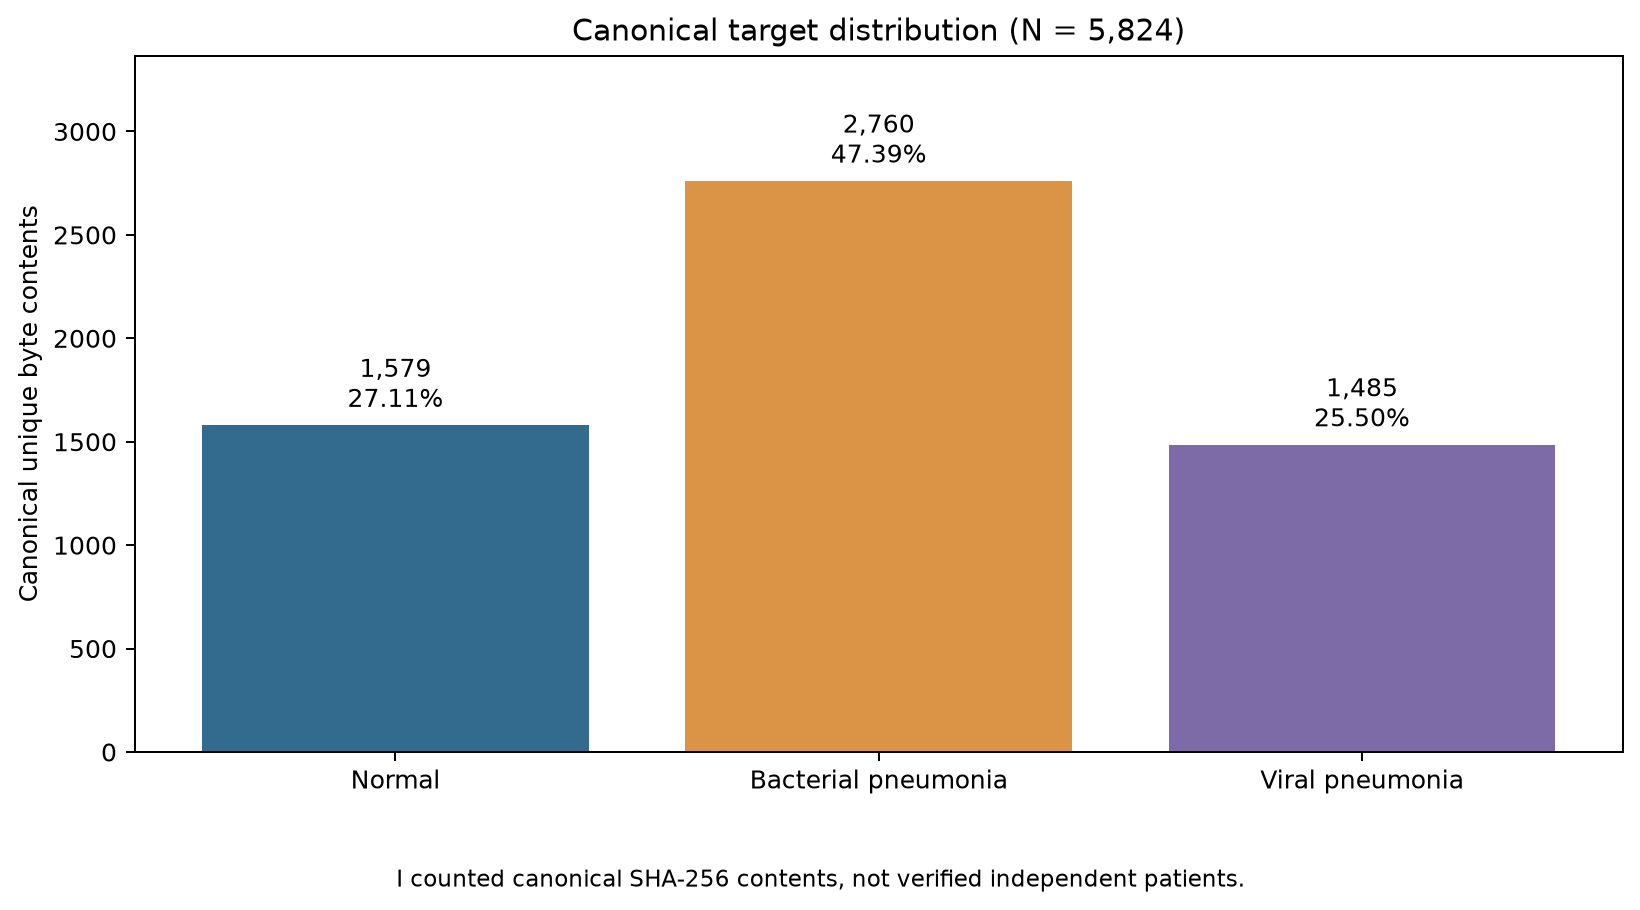

I observed the displayed role sizes and class proportions. Group integrity takes priority over exact balance; I do not interpret stratification as proof of statistical independence.

In [4]:
assignments = read_table(OUT / 'phase2_fold_assignments.csv')
folds = read_table(OUT / 'phase2_fold_summary.csv')
display(folds[folds.role.isin(['development','evaluation'])].reset_index(drop=True))
display(Image(filename=str(PROJECT/'figures/fig1_2_target_distribution.png')))
display(Markdown('I observed the displayed role sizes and class proportions. Group integrity takes priority over exact balance; I do not interpret stratification as proof of statistical independence.'))

## 5. Internal validation and training-only class weights

The first partition of an inner ten-fold `StratifiedGroupKFold`, seeded with 42 + outer-fold number, reserves approximately one tenth of development for internal validation. Group integrity takes priority over exact percentages. Class weights are calculated as `N_train / (3 * n_class_train)` using actual training labels only.

In [5]:
display(folds[folds.role.isin(['train','validation','evaluation'])].reset_index(drop=True))
weights = read_table(OUT/'phase2_class_weights.csv')
display(weights)
display(Markdown('I recorded exact train/validation/evaluation counts and per-fold weights above. I did not calculate fitting weights from the full canonical distribution.'))

,outer_fold,role,n,cohort_fraction,groups,NORMAL,NORMAL_fraction,BACTERIAL_PNEUMONIA,BACTERIAL_PNEUMONIA_fraction,VIRAL_PNEUMONIA,VIRAL_PNEUMONIA_fraction
0,1,train,4191,0.719609,2152,1136,0.271057,1986,0.473873,1069,0.255070
1,1,validation,468,0.080357,237,127,0.271368,222,0.474359,119,0.254274
2,1,evaluation,1165,0.200034,537,316,0.271245,552,0.473820,297,0.254936
3,2,train,4192,0.719780,2186,1136,0.270992,1986,0.473760,1070,0.255248
4,2,validation,466,0.080014,138,127,0.272532,221,0.474249,118,0.253219
5,2,evaluation,1166,0.200206,602,316,0.271012,553,0.474271,297,0.254717
6,3,train,4195,0.720295,2195,1137,0.271037,1989,0.474136,1069,0.254827
7,3,validation,466,0.080014,141,127,0.272532,220,0.472103,119,0.255365
8,3,evaluation,1163,0.199691,590,315,0.270851,551,0.473775,297,0.255374
9,4,train,4192,0.719780,2190,1136,0.270992,1987,0.473998,1069,0.255010


,outer_fold,target_label,class_index,training_count,weight
0,1,NORMAL,0,1136,1.229754
1,1,BACTERIAL_PNEUMONIA,1,1986,0.703424
2,1,VIRAL_PNEUMONIA,2,1069,1.306829
3,2,NORMAL,0,1136,1.230047
4,2,BACTERIAL_PNEUMONIA,1,1986,0.703592
5,2,VIRAL_PNEUMONIA,2,1070,1.305919
6,3,NORMAL,0,1137,1.229845
7,3,BACTERIAL_PNEUMONIA,1,1989,0.703033
8,3,VIRAL_PNEUMONIA,2,1069,1.308076
9,4,NORMAL,0,1136,1.230047


I recorded exact train/validation/evaluation counts and per-fold weights above. I did not calculate fitting weights from the full canonical distribution.

## 6. On-demand image preprocessing

Canonical loading verifies the source hash. L images supply their stored intensity; RGB images must have three pixel-identical channels before one channel is retained. Antialiased bilinear resizing preserves aspect ratio, followed by black symmetric padding to a 224 x 224 canvas. Odd padding is allocated to the bottom/right. The custom-model representation is an H x W float32 array divided by 255; no transformed dataset is saved.

Pretrained inputs optionally replicate intensity to CHW. Selected weights' published normalization must be supplied explicitly, without silently applying another crop or resize. No pretrained weights were selected at this checkpoint.

In [6]:
demonstrations = []
for mode in ['L','RGB']:
    row = canonical[canonical.image_mode==mode].iloc[0]
    intensity = load_canonical_image(PROJECT/'chest_xray', row)
    repeated = pretrained_representation(intensity)
    resized, padding = resize_geometry(int(row.width), int(row.height))
    demonstrations.append(dict(source_mode=mode, source_size=(int(row.width),int(row.height)), resized_size=resized, padding_ltrb=padding, output_shape=intensity.shape, dtype=str(intensity.dtype), minimum=float(intensity.min()), maximum=float(intensity.max()), pretrained_shape=repeated.shape))
display(pd.DataFrame(demonstrations))
display(Markdown('I observed the calculated geometry, output shapes, and ranges above. I preserved the source bytes, and repeated channels add no new information.'))
augmentation = AugmentationConfig(rotation_degrees=5, translation_fraction=.02)
display(augmentation)
display(Markdown('I configured training-only rotation and translation with explicit sample/epoch seeds. Validation/evaluation augmentation requests raise an error. I did not perform model training or augment held-out data.'))

,source_mode,source_size,resized_size,padding_ltrb,output_shape,dtype,minimum,maximum,pretrained_shape
0,L,"(936, 728)","(224, 174)","(0, 25, 0, 25)","(224, 224)",float32,0.0,0.843137,"(3, 224, 224)"
1,RGB,"(679, 304)","(224, 100)","(0, 62, 0, 62)","(224, 224)",float32,0.0,0.701961,"(3, 224, 224)"


I observed the calculated geometry, output shapes, and ranges above. I preserved the source bytes, and repeated channels add no new information.

AugmentationConfig(rotation_degrees=5, translation_fraction=0.02)

I configured training-only rotation and translation with explicit sample/epoch seeds. Validation/evaluation augmentation requests raise an error. I did not perform model training or augment held-out data.

## 7. Metadata diagnostic Pipeline and ColumnTransformer

The six documented numeric candidates are width, height, aspect ratio, file size, mean intensity, and intensity SD. A numeric `ColumnTransformer` contains `StandardScaler`, followed by the documented rank-VIF reduction rule. Each fold is fitted independently on its actual training rows.

I omitted nominal storage-mode fields because the equal-channel partition is redundant and adds no chromatic information. No one-hot predictor encoding is needed. The nominal target mapping remains separate from X.

In [7]:
display(pd.Series(summary['class_index'], name='Nominal target index').to_frame())
display(pd.DataFrame([dict(column=k, exclusion_reason=v) for k,v in summary['excluded_columns'].items()]))
display(pd.DataFrame([{k:v for k,v in d.items() if k in ['outer_fold','fit_rows','input_features','output_features','retained_columns','training_hash_fingerprint','scaler_fit_count_verified']} for d in summary['fold_diagnostics']]))
display(Markdown('I used explicit predictor lists and remainder=drop, so target, path/hash/identity tokens, source split, alternative annotations, and status fields cannot enter the diagnostic predictor matrix. No metadata enters the image branch.'))

,Nominal target index
NORMAL,0
BACTERIAL_PNEUMONIA,1
VIRAL_PNEUMONIA,2


,column,exclusion_reason
0,filepath,"I exclude identifiers, provenance, parsing/qua..."
1,filename,"I exclude identifiers, provenance, parsing/qua..."
2,original_split,"I exclude identifiers, provenance, parsing/qua..."
3,original_folder,"I exclude identifiers, provenance, parsing/qua..."
4,target_label,I use this nominal label as Y only.
5,patient_id_if_parseable,"I exclude identifiers, provenance, parsing/qua..."
6,patient_id_status,"I exclude identifiers, provenance, parsing/qua..."
7,label_parse_status,"I exclude identifiers, provenance, parsing/qua..."
8,label_parse_reason,"I exclude identifiers, provenance, parsing/qua..."
9,image_mode,I omit redundant storage/channel encodings aft...


,outer_fold,fit_rows,training_hash_fingerprint,input_features,output_features,retained_columns,scaler_fit_count_verified
0,1,4191,4130fff4c57761064091d4cab1b80cb1c647904b0dfd55...,6,4,"[width, file_size_bytes, mean_intensity, std_i...",True
1,2,4192,8a46aaac5d8b81606eba9b2aa32317e4a417ea30e7a364...,6,4,"[width, file_size_bytes, mean_intensity, std_i...",True
2,3,4195,c2e23fb13039139c6735bbde47f800b121cb7784648314...,6,4,"[width, file_size_bytes, mean_intensity, std_i...",True
3,4,4192,c9e56ebacfe4077b688c5c4211b325ce9a7303e3eb894e...,6,4,"[width, file_size_bytes, mean_intensity, std_i...",True
4,5,4194,d3a1e763122e4c00d646d4b1d34e32d27b31f06bef18d7...,6,4,"[width, file_size_bytes, mean_intensity, std_i...",True


I used explicit predictor lists and remainder=drop, so target, path/hash/identity tokens, source split, alternative annotations, and status fields cannot enter the diagnostic predictor matrix. No metadata enters the image branch.

## 8. Missingness

Original and canonical missingness are reproduced with only empty CSV fields interpreted as missing. Structural error-field blanks, unavailable identity tokens, and diagnostic measurement missingness are separate categories. Identity and nonpredictor fields are not imputed.

,dataset,record_type,column_name,missing_count,missing_percentage,total_rows,total_columns,total_matrix_cells,total_missing_cells,overall_missing_percentage,complete_rows,rows_with_missing_values,complete_rows_excluding_optional_errors
25,original_audit,MATRIX_SUMMARY,ALL,96864,22.054645,17568.0,25.0,439200.0,96864.0,22.054645,0.0,17568.0,8544.0
59,canonical_manifest,MATRIX_SUMMARY,ALL,13228,6.882701,5824.0,33.0,192192.0,13228.0,6.882701,0.0,5824.0,4244.0


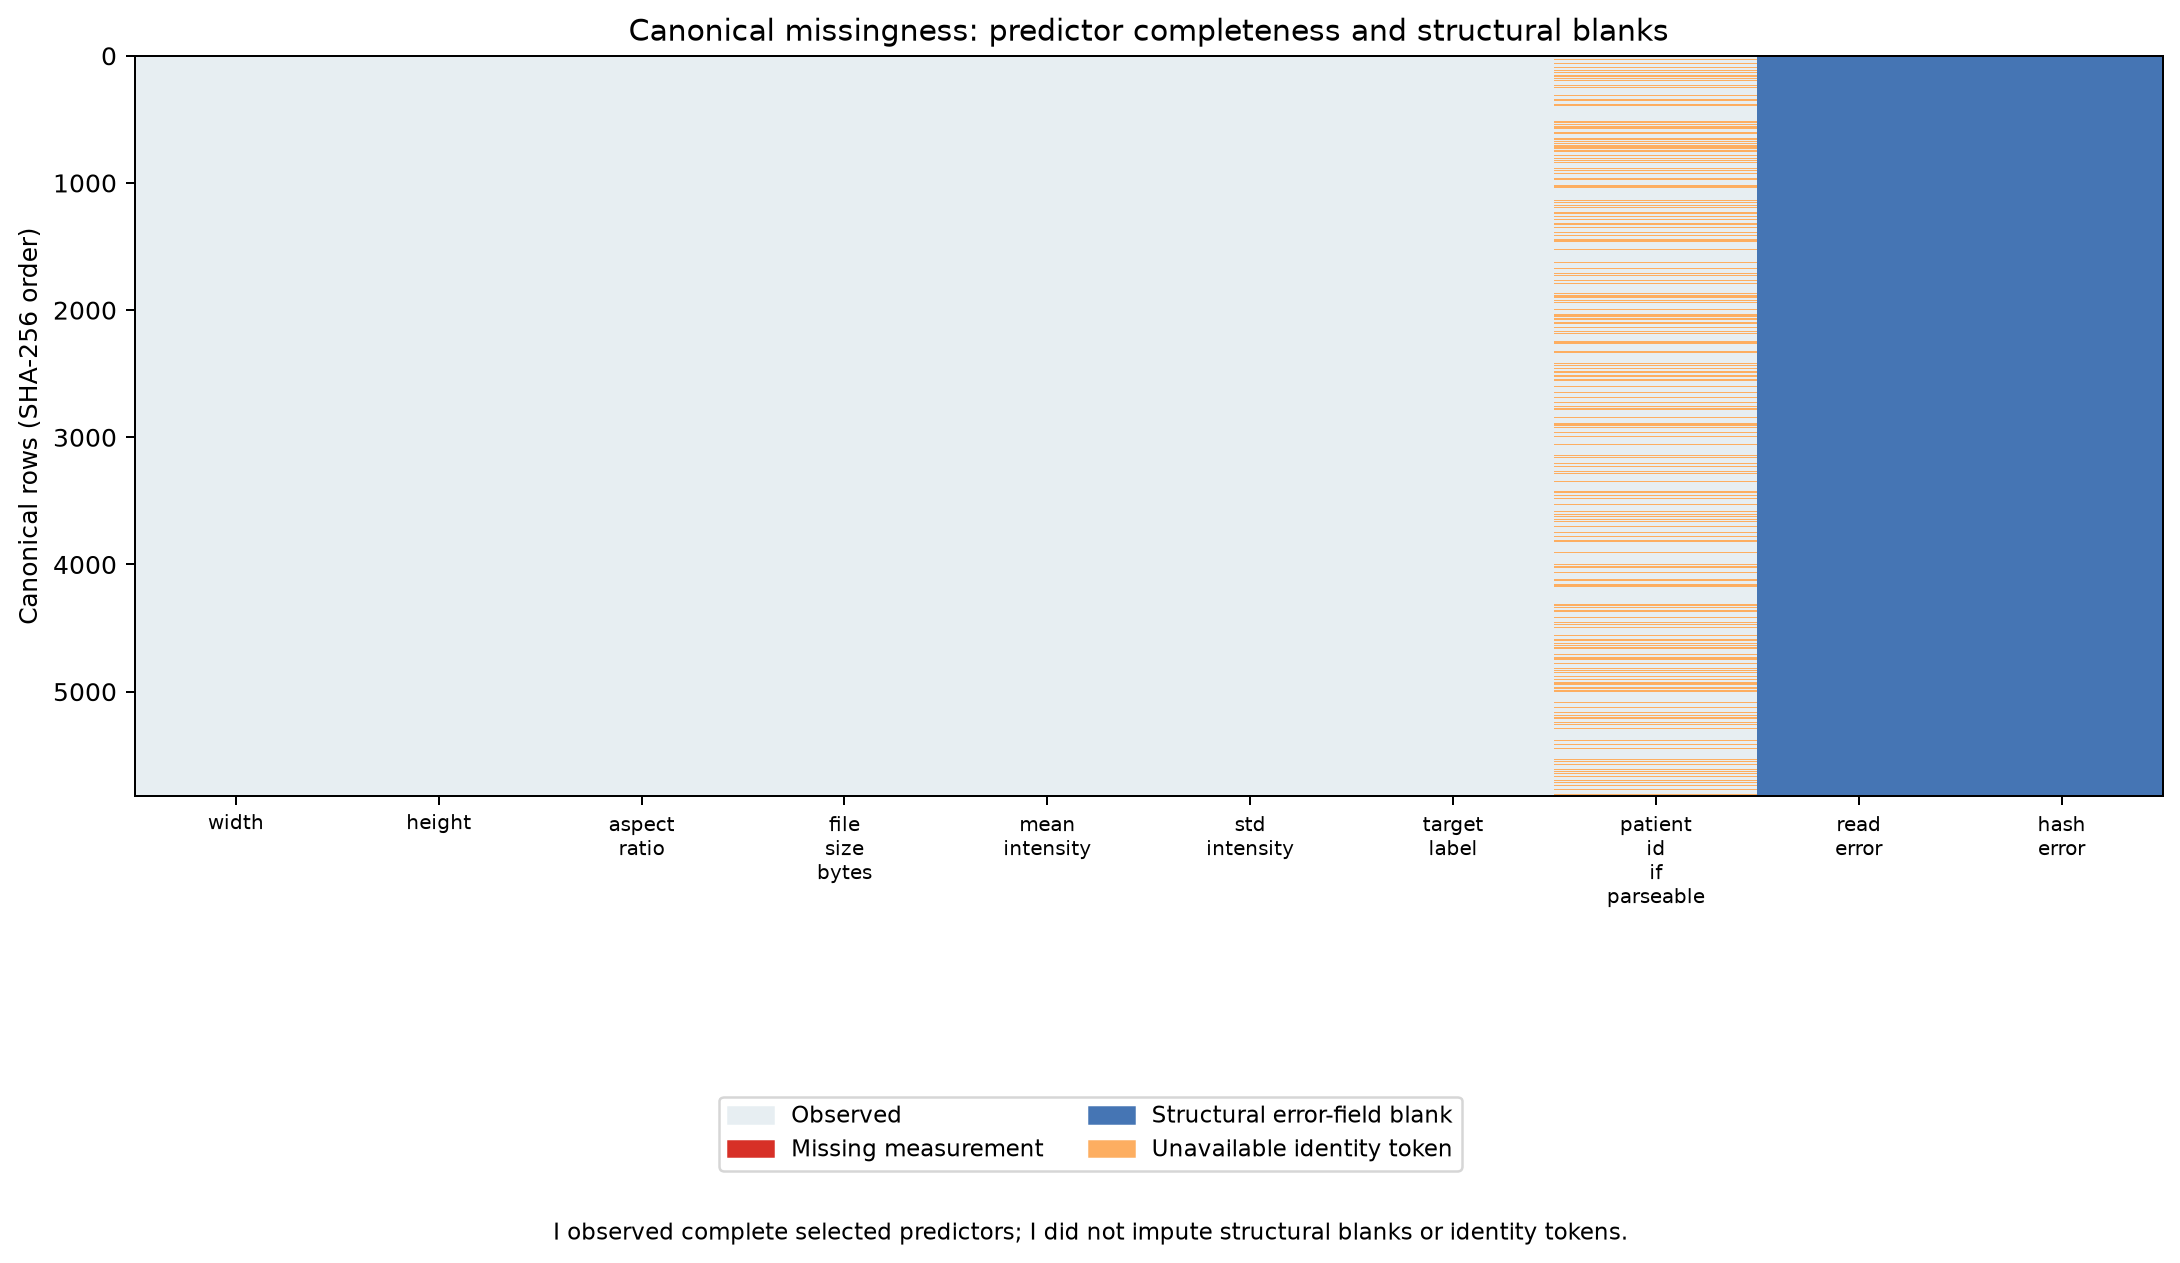

I observed **0 missing cells** in the six selected canonical diagnostic predictors, so I did not add an imputer. The canonical matrix contains 11,648 structural error blanks and 1,580 unavailable candidate tokens; these are not predictor measurements.

In [8]:
missing = read_table(OUT/'phase2_missingness_summary.csv')
display(missing[missing.record_type=='MATRIX_SUMMARY'])
display(Image(filename=str(PROJECT/'figures/fig1_1_missingness_heatmap.png')))
display(Markdown(f"I observed **{summary['missingness']['selected_predictor_missing_cells']} missing cells** in the six selected canonical diagnostic predictors, so I did not add an imputer. The canonical matrix contains {summary['missingness']['structural_error_blanks']:,} structural error blanks and {summary['missingness']['unavailable_candidate_ids']:,} unavailable candidate tokens; these are not predictor measurements."))

## 9. Metadata outlier comparison

Class-blind IQR fences are learned separately within each actual training subset. The intensity summaries retain a |Z| > 3 sensitivity comparison using training population SD. Capping is applied only to a temporary metadata comparison table. No CNN pixels are capped, no radiographs are deleted, and capping is not a retained pipeline stage. The required boxplots represent Fold 1 actual training data.

,outer_fold,variable,training_n,lower_fence,upper_fence,iqr_flagged,z_gt_3_sensitivity,skew_before,skew_after_diagnostic_cap,pixels_capped,cap_used_in_pipeline
0,1,width,4191,291.000000,2331.000000,50,NaN,0.601920,0.485273,False,False
1,1,height,4191,-72.500000,1955.500000,86,NaN,0.939673,0.730764,False,False
2,1,aspect_ratio,4191,0.768930,2.080986,67,NaN,1.085689,0.478165,False,False
3,1,file_size_bytes,4191,-227968.750000,529033.250000,550,NaN,2.633768,1.144338,False,False
4,1,mean_intensity,4191,77.459822,168.241096,76,16.0,-0.046336,-0.060790,False,False
5,1,std_intensity,4191,31.090870,83.149051,25,15.0,-0.214273,-0.180088,False,False
6,2,width,4192,297.000000,2321.000000,57,NaN,0.634345,0.493095,False,False
7,2,height,4192,-66.875000,1946.125000,86,NaN,0.995671,0.734131,False,False
8,2,aspect_ratio,4192,0.786373,2.059103,76,NaN,1.162576,0.469763,False,False
9,2,file_size_bytes,4192,-216731.625000,510051.375000,569,NaN,2.799884,1.127414,False,False


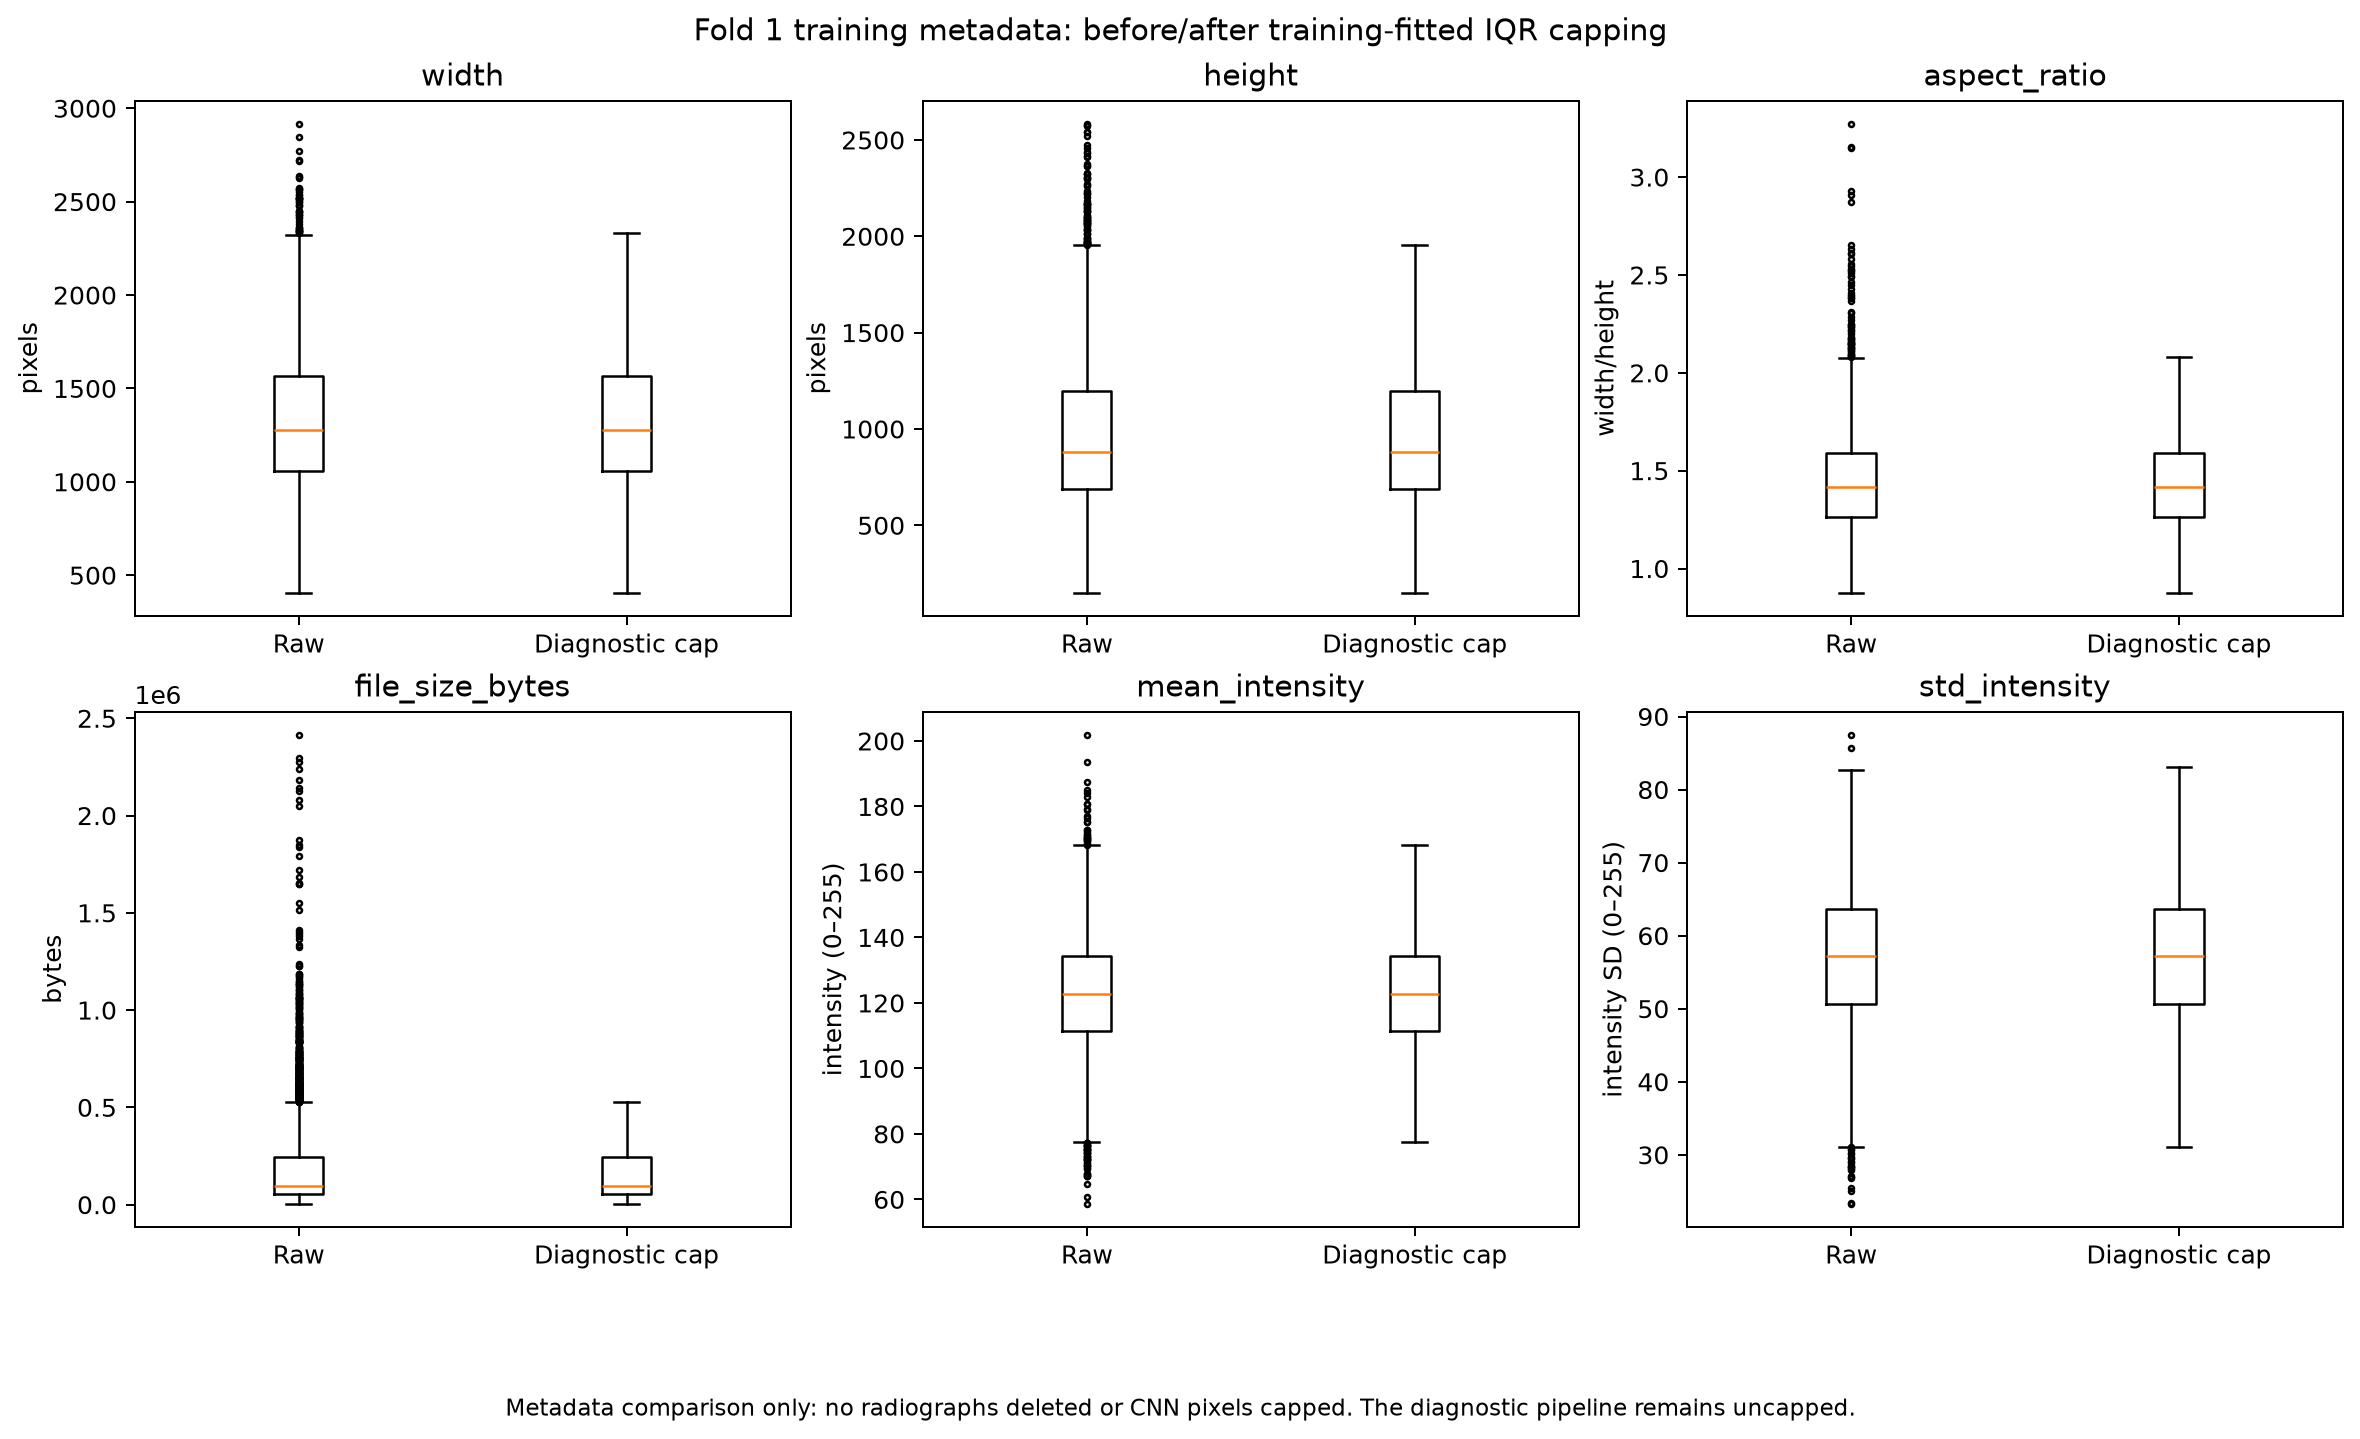

I observed 729 fold-1 training images with at least one metadata IQR flag. This result supports review prioritization and does not justify deleting images or altering pixels. Training-fitted thresholds differ from full-cohort Phase 1 descriptive thresholds because their populations differ.

In [9]:
outliers = read_table(OUT/'phase2_outliers_summary.csv')
display(outliers)
display(Image(filename=str(PROJECT/'figures/fig2_1_outlier_boxplots.png')))
display(Markdown(f"I observed {summary['fold_diagnostics'][0]['iqr_flagged_training_images']} fold-1 training images with at least one metadata IQR flag. This result supports review prioritization and does not justify deleting images or altering pixels. Training-fitted thresholds differ from full-cohort Phase 1 descriptive thresholds because their populations differ."))

## 10. Correlation and collinearity

Spearman correlations are computed from actual training rows. The required correlation figure and scatterplots represent Fold 1 training data; they are not full-cohort fitted preprocessing summaries.

Raw and rank VIF are retained as diagnostics. When rank-VIF indicates redundancy, structurally derived aspect ratio is removed first. Rank-VIF is recomputed; values above 10 are removed from largest downward, with ties within 0.01 resolved by weaker training MI then alphabetically. This rule affects metadata only, not spatial image pixels.

,outer_fold,variable_1,variable_2,spearman_rho
9,1,file_size_bytes,height,0.937291
1,1,height,width,0.930724
3,1,file_size_bytes,width,0.912075
5,1,std_intensity,width,0.519663
33,1,file_size_bytes,std_intensity,0.502074
31,1,height,std_intensity,0.449969


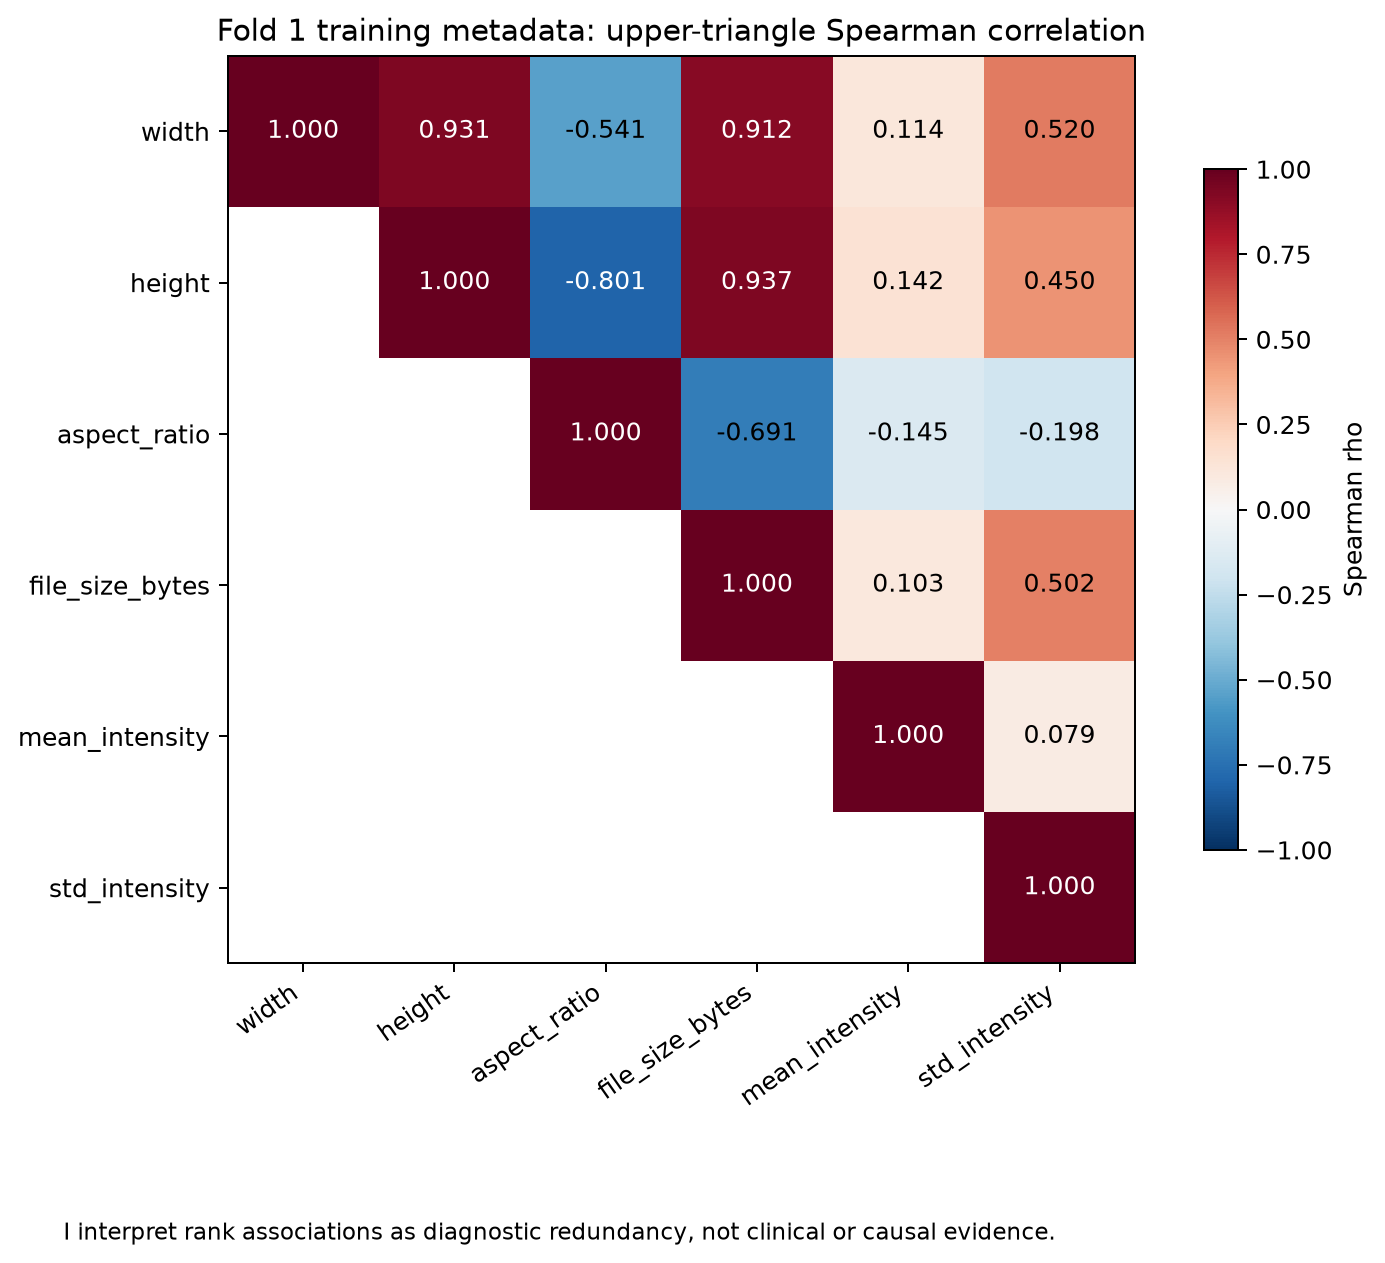

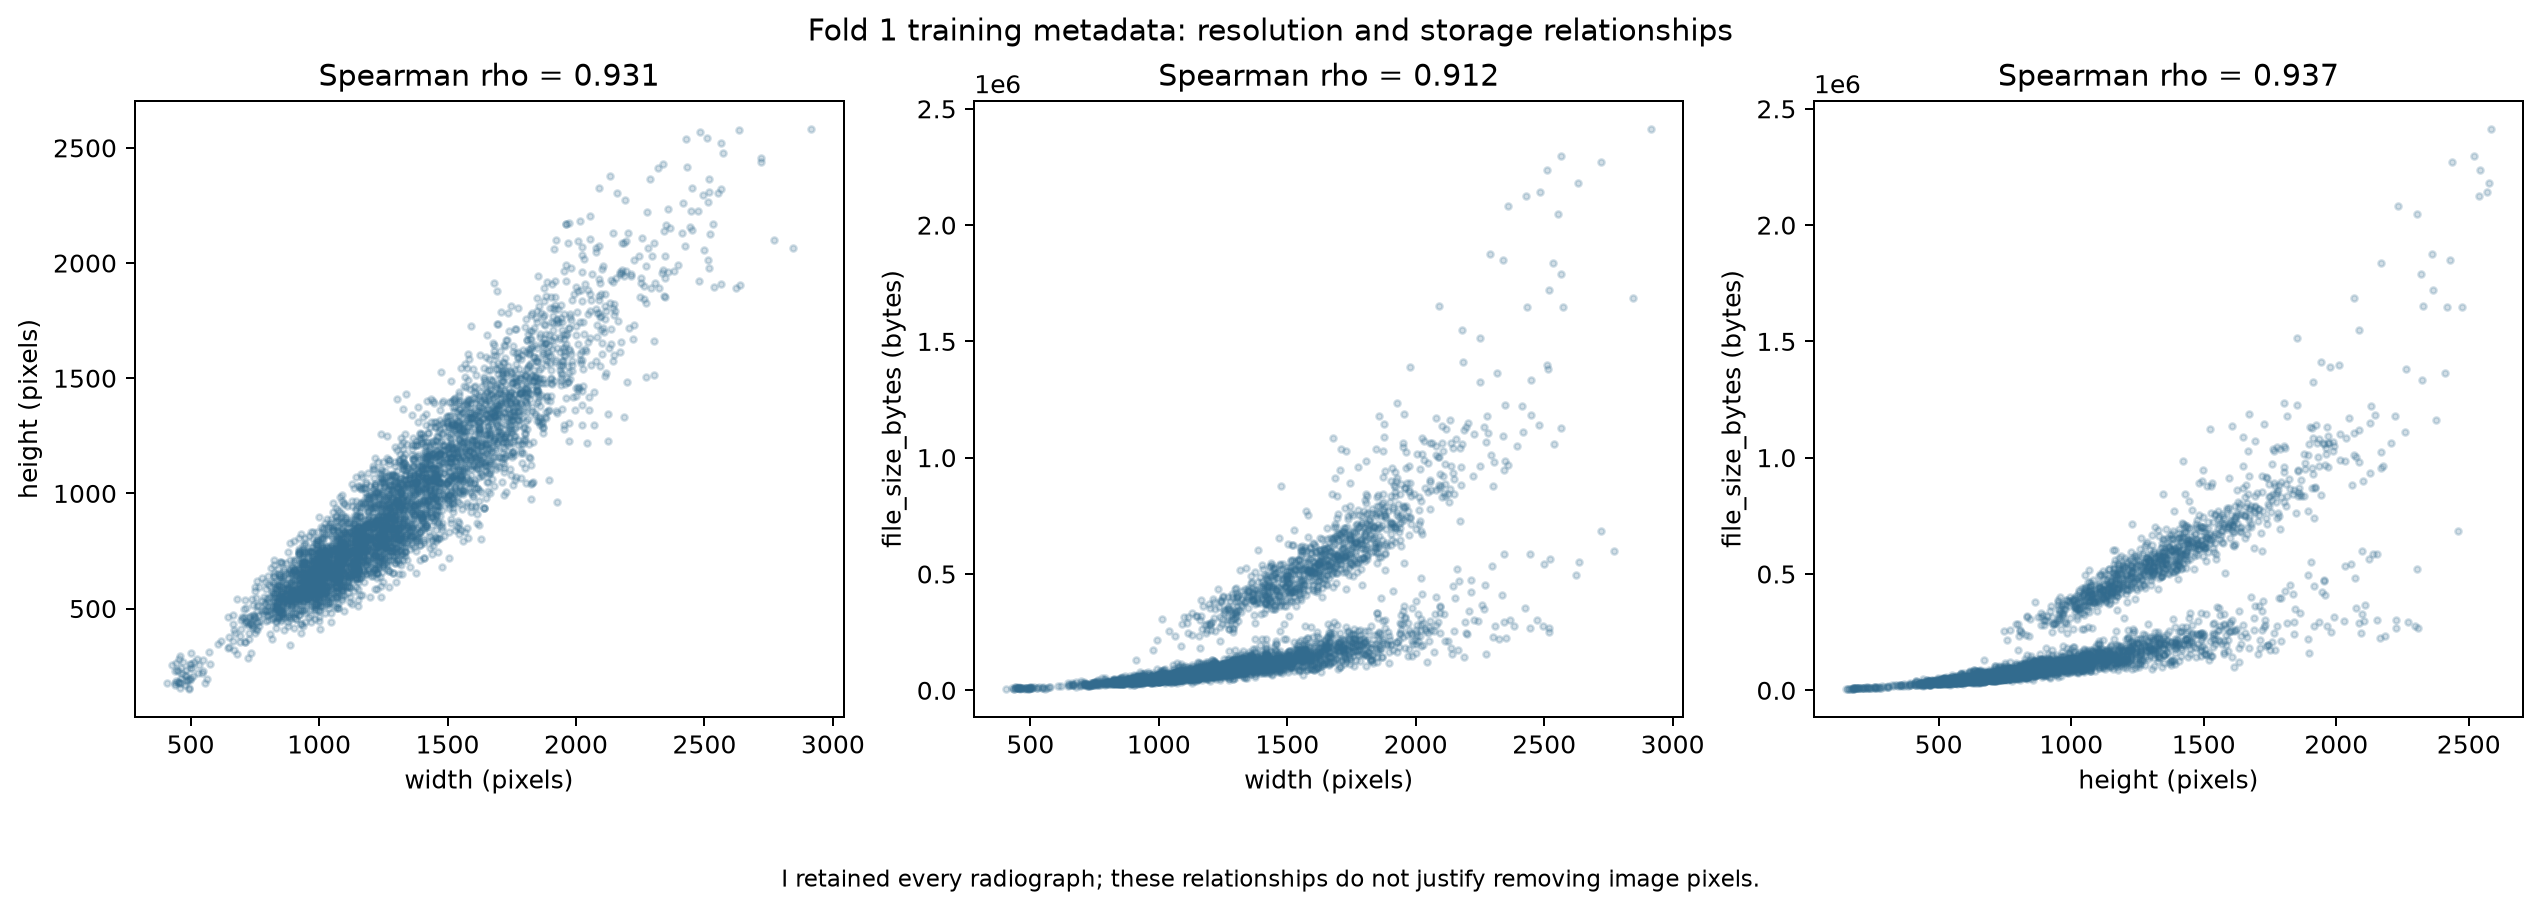

,outer_fold,stage,variable,N,auxiliary_R_squared,VIF,VIF_gt_10,auxiliary_design_rank,intercept_included,used_as_CNN_feature
0,1,raw_initial,width,4191,0.939092,16.418091,True,6,True,False
1,1,raw_initial,height,4191,0.969042,32.302148,True,6,True,False
2,1,raw_initial,aspect_ratio,4191,0.784487,4.640102,False,6,True,False
3,1,raw_initial,file_size_bytes,4191,0.691554,3.242062,False,6,True,False
4,1,raw_initial,mean_intensity,4191,0.034219,1.035431,False,6,True,False
5,1,raw_initial,std_intensity,4191,0.245327,1.325078,False,6,True,False
6,1,rank_initial,width,4191,0.983538,60.747262,True,6,True,False
7,1,rank_initial,height,4191,0.991751,121.224034,True,6,True,False
8,1,rank_initial,aspect_ratio,4191,0.955226,22.334507,True,6,True,False
9,1,rank_initial,file_size_bytes,4191,0.894587,9.486501,False,6,True,False


I implemented the fold-1 removals `[{'column': 'aspect_ratio', 'reason': 'structurally derived redundancy first'}, {'column': 'height', 'reason': 'largest rank-VIF > threshold; MI then alphabetical ties'}]` and retained `['width', 'file_size_bytes', 'mean_intensity', 'std_intensity']`. The full CSV records each fold separately. I interpret the observed relationships as acquisition/storage redundancy, not a reason to modify radiographs.

In [10]:
corr = read_table(OUT/'phase2_correlation_summary.csv')
display(corr[(corr.outer_fold==1)&(corr.variable_1<corr.variable_2)].sort_values('spearman_rho',ascending=False).head(6))
display(Image(filename=str(PROJECT/'figures/fig3_1_correlation_matrix.png')))
display(Image(filename=str(PROJECT/'figures/fig3_2_collinear_scatterplots.png')))
vif = read_table(OUT/'phase2_vif_summary.csv')
display(vif[vif.outer_fold==1])
display(Markdown(f"I implemented the fold-1 removals `{summary['fold_diagnostics'][0]['removed_columns']}` and retained `{summary['fold_diagnostics'][0]['retained_columns']}`. The full CSV records each fold separately. I interpret the observed relationships as acquisition/storage redundancy, not a reason to modify radiographs."))

## 11. Multiclass feature-target association

The Phase 1 estimator uses ten-quantile-bin plug-in mutual information in nats, dropping duplicate quantile boundaries. Seed 42 and 499 label permutations describe finite-sample reference bias. Each outer fold's actual training subset is analyzed separately.

The required figure summarizes the mean and sample SD across five training subsets. These subsets overlap, so SD describes variation across training allocations rather than independent uncertainty or a confidence interval. Image-level permutation references are not patient-independent significance tests. Association does not establish causation or clinical importance.

,variable,mean_mi_nats,sd_mi_nats,min_mi_nats,max_mi_nats,fold1_mi_nats,fold_count
0,file_size_bytes,0.449173,0.004304,0.446598,0.456767,0.456767,5
1,height,0.267537,0.007010,0.258114,0.277416,0.267032,5
2,width,0.235558,0.006492,0.227681,0.242067,0.238226,5
3,aspect_ratio,0.157812,0.002819,0.154798,0.161008,0.161008,5
4,std_intensity,0.131843,0.004893,0.124322,0.138025,0.138025,5
5,mean_intensity,0.025091,0.001023,0.024187,0.026251,0.024262,5


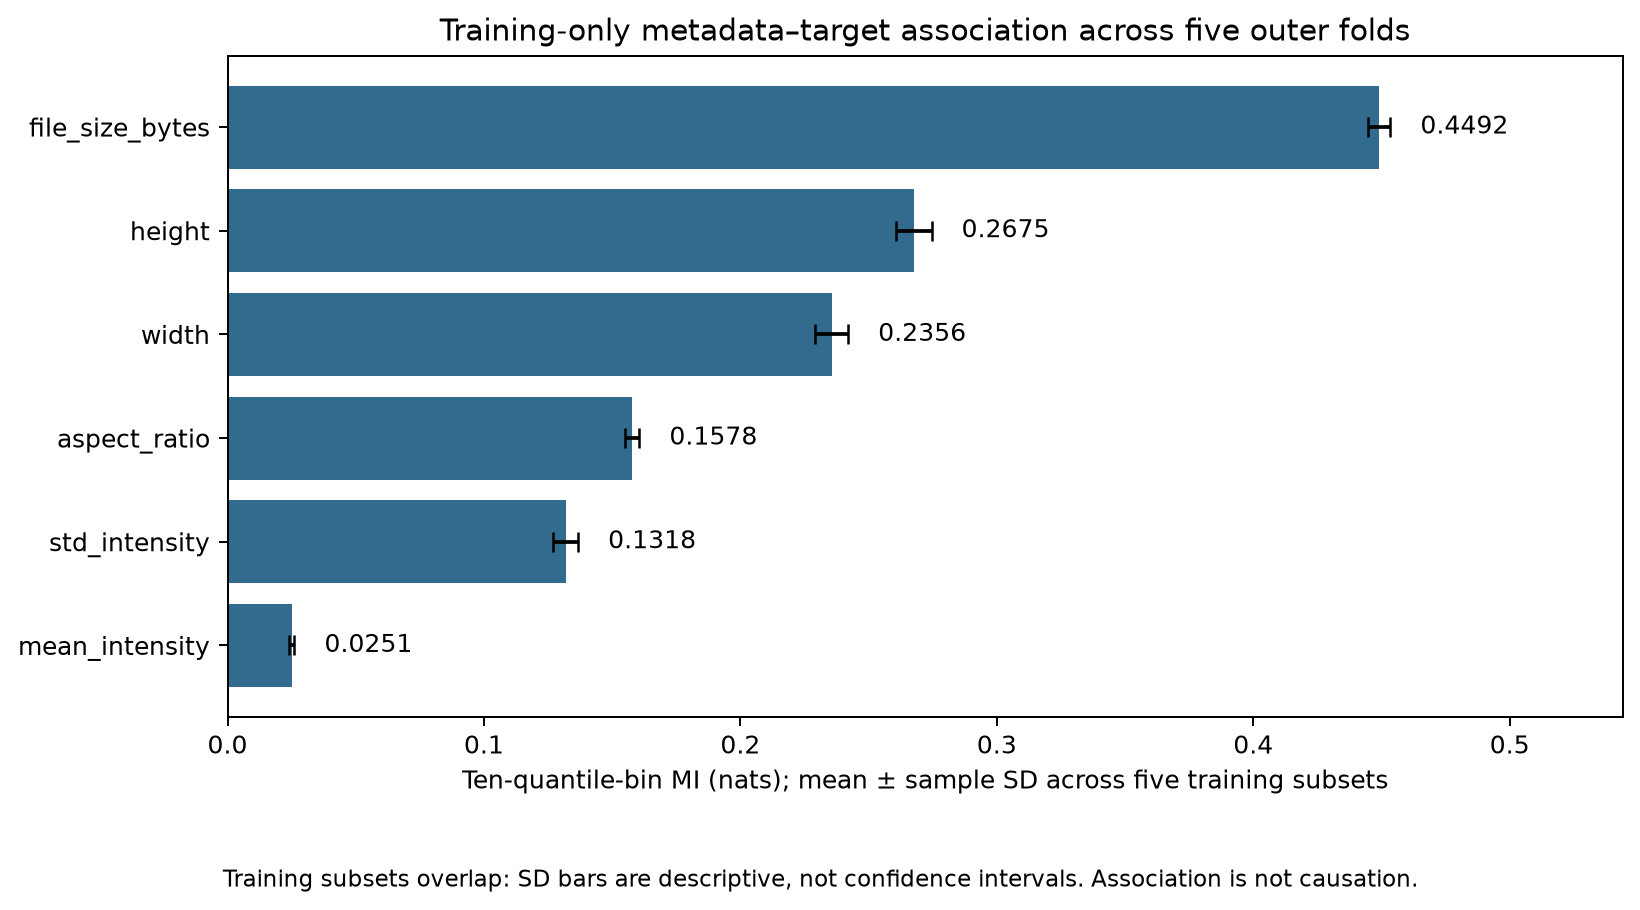

The strongest mean binned association is **file_size_bytes**, MI = **0.4492 nats**, with descriptive across-fold SD **0.0043**. This supports investigating acquisition/shortcut signals without identifying a causal mechanism. The independently computed fold records are retained in `phase2_associations_summary.csv`.

In [11]:
associations = read_table(OUT/'phase2_associations_summary.csv')
across_folds = read_table(OUT/'phase2_associations_across_folds.csv')
display(across_folds)
display(Image(filename=str(PROJECT/'figures/fig3_3_target_importance.png')))
top = across_folds.sort_values('mean_mi_nats',ascending=False).iloc[0]
display(Markdown(f"The strongest mean binned association is **{top.variable}**, MI = **{top.mean_mi_nats:.4f} nats**, with descriptive across-fold SD **{top.sd_mi_nats:.4f}**. This supports investigating acquisition/shortcut signals without identifying a causal mechanism. The independently computed fold records are retained in `phase2_associations_summary.csv`."))

## 12. Transformation comparison

Positive `file_size_bytes` is justified by the Phase 1 skew analysis. Fold 1 actual training data are shown as raw bytes, log1p(raw bytes), MinMaxScaler(raw bytes), and StandardScaler(raw bytes). The two scalers are fitted independently on training raw bytes. Panel order does not imply a sequential MinMax-to-StandardScaler pipeline. Positive finite values are required before log1p is computed.

,outer_fold,panel,skewness,mean,population_sd,minimum,maximum
0,1,Raw,2.633768,2.126720e+05,266373.814285,5644.000000,2.414342e+06
1,1,Log1p(raw),0.469678,1.169975e+01,1.025523,8.638525,1.469694e+01
2,1,MinMax(raw),2.633768,8.595015e-02,0.110588,0.000000,1.000000e+00
3,1,Standardized(raw),2.633768,1.525861e-17,1.000000,-0.777208,8.265340e+00


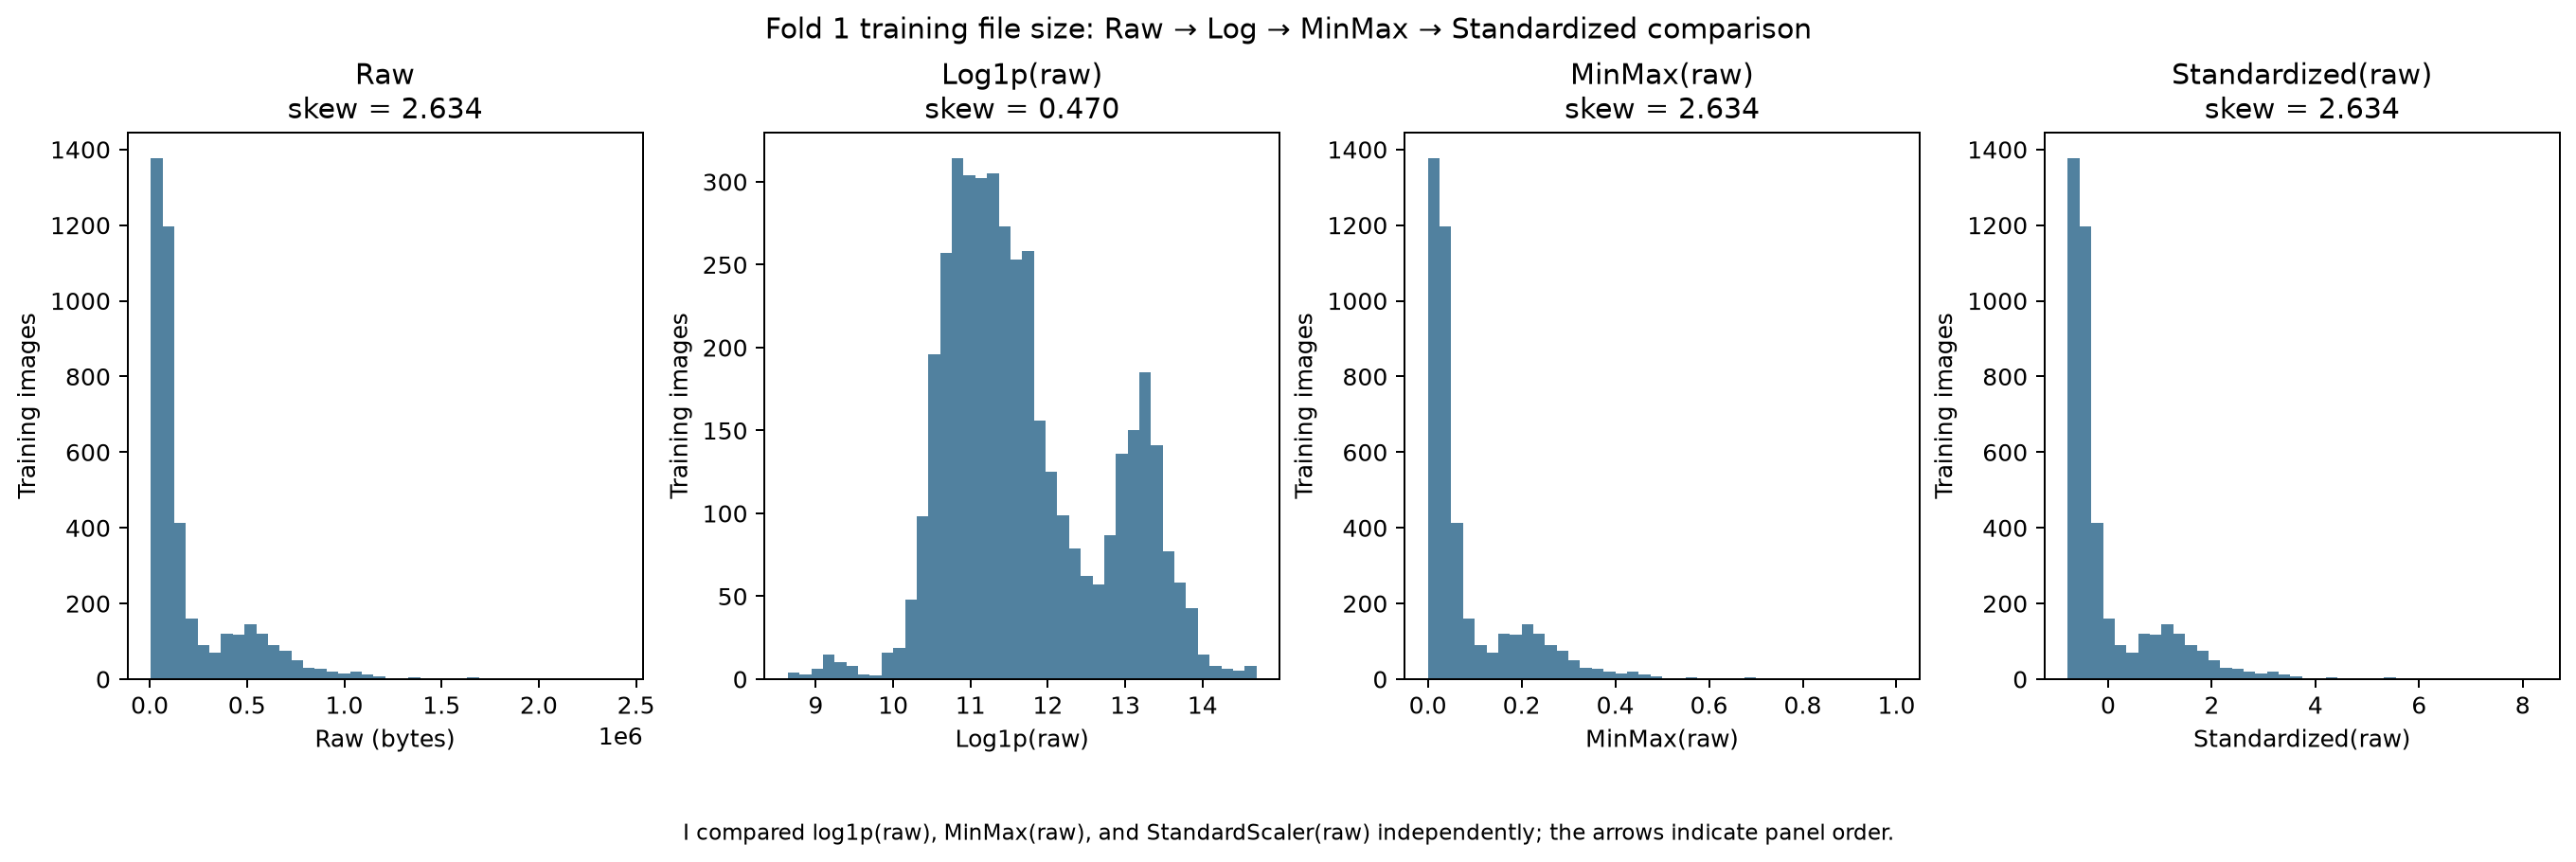

I observed raw skew **2.6338** and log1p skew **0.4697** in fold-1 training metadata. Affine MinMax and standard scaling change units and spread while retaining skew. This comparison does not automatically justify a log transform in the retained pipeline.

In [12]:
transforms = read_table(OUT/'phase2_transform_stats_summary.csv')
display(transforms[transforms.outer_fold==1])
display(Image(filename=str(PROJECT/'figures/fig4_1_transformation_grid.png')))
d = summary['fold_diagnostics'][0]
display(Markdown(f"I observed raw skew **{d['raw_file_size_skew']:.4f}** and log1p skew **{d['log_file_size_skew']:.4f}** in fold-1 training metadata. Affine MinMax and standard scaling change units and spread while retaining skew. This comparison does not automatically justify a log transform in the retained pipeline."))

## 13. PCA methodology comparison

Two full-SVD PCA spaces are fitted independently within each actual training subset:

A. Six standardized candidate metadata variables, before collinearity reduction, as an exploratory redundancy diagnostic.

B. The standardized output of that fold's fitted diagnostic pipeline, after collinearity reduction. The existing fitted pipeline is transformed without refitting.

I selected B for the required figure because it describes the implemented pipeline's output space, regardless of how many components reach the variance thresholds. A remains available in `phase2_pca_comparison.csv`. Neither PCA is applied to CNN pixels or automatically retained as a predictor stage. The required figure represents Fold 1 actual training data.

,outer_fold,scope,component,explained_variance_ratio,cumulative_explained_variance,feature_count,components_90,components_95
0,1,six_candidate_variables_pre_collinearity,1,0.567935,0.567935,6,4,4
1,1,six_candidate_variables_pre_collinearity,2,0.163580,0.731515,6,4,4
2,1,six_candidate_variables_pre_collinearity,3,0.143283,0.874799,6,4,4
3,1,six_candidate_variables_pre_collinearity,4,0.077988,0.952787,6,4,4
4,1,six_candidate_variables_pre_collinearity,5,0.043917,0.996703,6,4,4
5,1,six_candidate_variables_pre_collinearity,6,0.003297,1.000000,6,4,4
6,1,retained_pipeline_output_post_collinearity,1,0.516843,0.516843,4,3,4
7,1,retained_pipeline_output_post_collinearity,2,0.243938,0.760781,4,3,4
8,1,retained_pipeline_output_post_collinearity,3,0.179375,0.940155,4,3,4
9,1,retained_pipeline_output_post_collinearity,4,0.059845,1.000000,4,3,4


,outer_fold,scope,feature_count,components_90,components_95
0,1,six_candidate_variables_pre_collinearity,6,4,4
1,1,retained_pipeline_output_post_collinearity,4,3,4
2,2,six_candidate_variables_pre_collinearity,6,4,4
3,2,retained_pipeline_output_post_collinearity,4,3,4
4,3,six_candidate_variables_pre_collinearity,6,4,4
5,3,retained_pipeline_output_post_collinearity,4,3,4
6,4,six_candidate_variables_pre_collinearity,6,4,4
7,4,retained_pipeline_output_post_collinearity,4,3,4
8,5,six_candidate_variables_pre_collinearity,6,4,4
9,5,retained_pipeline_output_post_collinearity,4,3,4


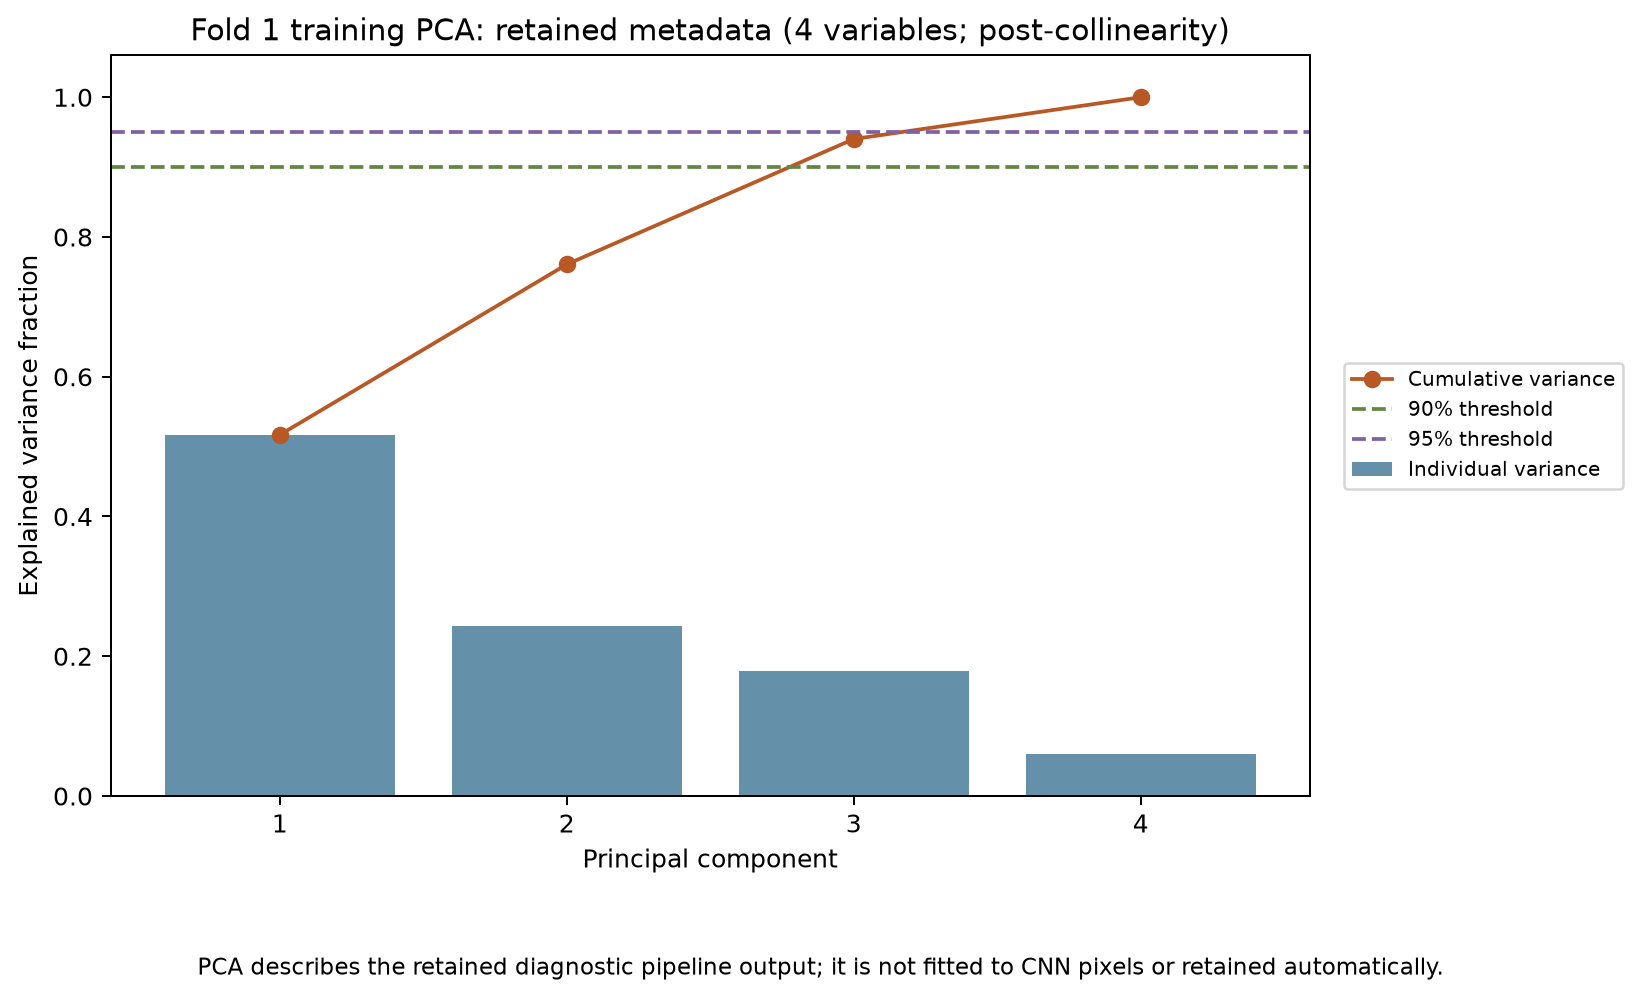

Post-collinearity Fold-1 training metadata reaches 90% variance in **3 components** and 95% in **4**. Candidate-space counts are **4 / 4**. The figure follows the retained pipeline output space; explained variance does not establish predictive or clinical utility.

In [13]:
pca = read_table(OUT/'phase2_pca_summary.csv')
pca_comparison = read_table(OUT/'phase2_pca_comparison.csv')
display(pca_comparison[pca_comparison.outer_fold.eq(1)])
display(pca_comparison[['outer_fold','scope','feature_count','components_90','components_95']].drop_duplicates().reset_index(drop=True))
display(Image(filename=str(PROJECT/'figures/fig5_1_pca_scree_plot.png')))
display(Markdown(f"Post-collinearity Fold-1 training metadata reaches 90% variance in **{summary['fold_diagnostics'][0]['pca_90_components']} components** and 95% in **{summary['fold_diagnostics'][0]['pca_95_components']}**. Candidate-space counts are **{summary['fold_diagnostics'][0]['pca_candidate_90_components']} / {summary['fold_diagnostics'][0]['pca_candidate_95_components']}**. The figure follows the retained pipeline output space; explained variance does not establish predictive or clinical utility."))

## 14. Output dimensionality

The six-candidate metadata input, retained metadata output, candidate-space PCA, retained-space PCA, and image intensity canvas are distinct representations. All PCA dimensions and variance thresholds are derived from executed training-only calculations.

In [14]:
display(pd.DataFrame([{k:d[k] for k in ['outer_fold','input_features','output_features','retained_columns']} for d in summary['fold_diagnostics']]))
display(Markdown(f"I produce {224*224:,} scaled intensity values per 224 × 224 image, or {3*224*224:,} repeated channel values when a pretrained input requires CHW replication. Repetition adds no independent intensity information."))

,outer_fold,input_features,output_features,retained_columns
0,1,6,4,"[width, file_size_bytes, mean_intensity, std_i..."
1,2,6,4,"[width, file_size_bytes, mean_intensity, std_i..."
2,3,6,4,"[width, file_size_bytes, mean_intensity, std_i..."
3,4,6,4,"[width, file_size_bytes, mean_intensity, std_i..."
4,5,6,4,"[width, file_size_bytes, mean_intensity, std_i..."


I produce 50,176 scaled intensity values per 224 × 224 image, or 150,528 repeated channel values when a pretrained input requires CHW replication. Repetition adds no independent intensity information.

## 15. Leakage and preservation assertions

Checks cover SHA isolation, filename-base and final-component isolation across all three roles, every unresolved edge, exactly-once outer evaluation coverage, predictor exclusions, and independent training scaler fits. Saved assignment identifiers are checked against canonical and grouping evidence. A counterfactual source-split replacement must leave assignments unchanged.

The final raw rehash includes notebook demonstrations. Phase 1 text contents are compared with committed evidence allowing Git's CRLF/LF checkout conversion; actual working byte hashes are checked before/after execution. The preserved Phase 1 figure is compared byte-for-byte with its committed original.

In [15]:
assert_partitions(grouped, assignments, candidates)
last_snapshot = raw_snapshot(PROJECT/'chest_xray')
assert snapshot_fingerprint(last_snapshot)==summary['raw_fingerprint_before']==summary['raw_fingerprint_after']
assert all(summary['leakage_assertions'].values())
assert not (set(summary['predictors']) & {'target_label','original_split','filepath','sha256_hash','filename','leakage_control_group','patient_id_if_parseable'})
assert all((PROJECT/'figures'/name).is_file() for name in FIGURES)
display(pd.Series(summary['leakage_assertions'],name='Passed').to_frame())
display(Markdown('I passed the displayed leakage and preservation assertions. These checks establish engineering isolation under the retained relation policy, while true patient independence remains unverified.'))
research_audit = json.loads((OUT/'phase2_research_audit.json').read_text())
display(pd.Series(research_audit['constraint_graph']).to_frame('Independent graph audit'))
display(Markdown(f"The independent graph reconstruction touches **{research_audit['constraint_graph']['components_touched_by_edges']} final components** and agrees with the saved split partition. Mixed-class components are allocation constraints, not patient identities. Phase 1 preservation checks cover **{research_audit['phase1_preservation']['protected_files_checked']} protected tracked files**; their working bytes remain unchanged."))

,Passed
sha_role_isolation,True
group_role_isolation,True
base_relation_isolation,True
phash_edge_isolation,True
evaluation_coverage_exactly_once,True
source_split_not_used,True
target_not_a_predictor,True
train_only_scaler_fits,True
raw_dataset_unchanged,True
phase1_tables_unchanged,True


I passed the displayed leakage and preservation assertions. These checks establish engineering isolation under the retained relation policy, while true patient independence remains unverified.

,Independent graph audit
phash_edges,223
base_groups,3117
final_components,2926
net_base_group_merges,191
components_touched_by_edges,66
unique_edge_endpoint_contents,262
largest_component_images,140
mixed_class_components,966
independent_graph_partition_matches,True
interpretation,Unresolved similarity edges constrain role all...


The independent graph reconstruction touches **66 final components** and agrees with the saved split partition. Mixed-class components are allocation constraints, not patient identities. Phase 1 preservation checks cover **89 protected tracked files**; their working bytes remain unchanged.

## 16. Strategy versus observed implementation

The decision log distinguishes confirmed Phase 1 decisions, operationalized decisions, audit refinements to PCA/MI presentation, and the genuine runtime deviation. The reduction from filename-only groups to constrained split components follows the Phase 1 policy and is not duplicate adjudication. Python 3.14.7 was recorded in Phase 1; Phase 2 executes with Python 3.12.14 while retaining dependency pins and the original tests.

In [16]:
display(Markdown((PROJECT/'phase2_implementation/phase2_decision_log.md').read_text(encoding='utf-8')))
display(Markdown('Canonical membership, channel handling, geometric preprocessing, training-only fitting, augmentation bounds, and review-only outlier handling confirm the Phase 1 design. Unresolved-edge constraints operationalize that design. The final audit aligned the required PCA figure with the retained feature space and expanded MI presentation across training folds. The different Python interpreter is explicitly recorded rather than presented as the same runtime.'))

# Phase 2 checkpoint decisions

I implemented two separate branches: image preprocessing for future CNN inputs and metadata diagnostics for acquisition/shortcut investigation. I did not train a CNN, finalize patient identities, or write a final Phase 2 report.

| Classification | Phase 1 plan | Phase 2 observed evidence | Implemented decision | Technical reason | Impact |
|---|---|---|---|---|---|
| Confirmed | One canonical path per readable SHA-256 | I verified 5824 rows and unchanged manifest bytes. | I retained all canonical contents for this checkpoint. | I found no new adjudicated exclusion evidence. | Membership is reproducible; patient independence remains unverified. |
| Confirmed | Filename-derived relation groups | I reproduced 3117 base groups. | I grouped pneumonia tokens across subtypes and kept Normal filename families distinct. | I followed the documented relation policy without asserting patient identity. | I retained the Phase 1 base structure. |
| Operationalized | Unresolved pHash edges stay within roles | I found 223 unresolved edges and 2926 constraint components. | I retained every unresolved edge as a split-only constraint. | I have no definitive adjudication establishing duplicates or rejected edges. | The partition group count differs from the filename-only count by design; I did not merge image contents. |
| Operationalized | Five group-aware outer folds; approximately 72/8/20 roles | I recorded all actual role/class/group counts in phase2_fold_summary.csv. | I used seed 42 for outer folds and seed 42+fold for the first inner ten-fold partition. | I prioritized component integrity and did not search favorable seeds. | Exact shares vary; all roles and candidate endpoints remain isolated. |
| Confirmed | 224×224 aspect-preserving common intensity input | I verified deterministic float32 [0,1] outputs for one L and one RGB canonical image. | I implemented antialiased bilinear resize, black symmetric padding, and bottom/right odd pixels. | I preserved stored geometry and equal-channel intensity. | Raw images remain read-only; inputs are produced on demand. |
| Operationalized | Conservative training-only augmentation | I tested bounded seeded rotation/translation; I did not train models. | I configured ±5° and up to 2% translation with explicit sample/epoch seeds. | I avoided another augmentation dependency. | Validation/evaluation reject augmentation requests. |
| Confirmed | No predictor imputation or pixel capping | I observed 0 missing predictor cells. | I retained structural blanks and used IQR caps for metadata comparison only. | Optional error fields and unverified IDs are not predictors. | No imputer, automatic exclusion, or pixel Winsorization is used. |
| Operationalized | Train-derived normalization and class weights | I independently fitted five training-only pipelines and computed five sets of class weights. | I calculate N_train/(3*n_class) for each active training subset. | I isolate fitted state from internal validation and outer evaluation. | Each fold records its training-hash fingerprint and scaler sample count. |
| Operationalized | Structural redundancy first, then rank-VIF >10 | I removed [{'column': 'aspect_ratio', 'reason': 'structurally derived redundancy first'}, {'column': 'height', 'reason': 'largest rank-VIF > threshold; MI then alphabetical ties'}] in fold 1; I recorded all fold-specific decisions. | I implemented the deterministic aspect-ratio-first and rank-VIF/MI tie rule. | I used training-only metadata and retained raw/rank VIF evidence. | Only the metadata diagnostic feature space changes; no spatial pixels are removed. |
| Operationalized | Skew/transformation diagnostics | Fold-1 raw/log skew is 2.6338/0.4697. | I compare raw/log1p/MinMax/standardized representations independently. | Affine scaling changes units and spread, not skew. | Log and capping remain diagnostic comparisons rather than retained pipeline stages. |
| Phase 2 methodological refinement | PCA diagnostics on standardized metadata | Fold-1 candidate-space PCA reaches 90%/95% at 4/4 components; retained-space PCA reaches them at 3/4. | I selected post-collinearity PCA for the required figure and retained both spaces in phase2_pca_comparison.csv. | The four-variable PCA describes the actual retained diagnostic pipeline output; selection was based on pipeline alignment, not the variance result. | The required PCA figure changed scope; PCA remains exploratory and is not added to the predictor pipeline. |
| Phase 2 presentation refinement | Training-only feature/target association | All five training-fold MI calculations are summarized in phase2_associations_across_folds.csv. | I replaced the representative fold-1 figure with the across-fold mean and sample SD. | A five-subset descriptive summary exposes stability; overlapping training sets preclude interpreting SD as independent uncertainty or a confidence interval. | Only the presentation changes; no full-cohort MI fitting or causal inference is introduced. |
| Operationalized | Preserve Phase 1 evidence | I found an exact required-filename collision for the correlation figure. | I preserved the committed bytes as figures/phase1_fig3_1_correlation_matrix.png. | I needed the exact Phase 2 deliverable filename. | Both the historical and current correlation figures remain available. |
| Genuine runtime deviation | Reproduce the environment | Phase 1 recorded Python 3.14.7; Phase 2 executed with Python 3.12.14. | I retained the Phase 1 dependency pins and tests, and added four necessary direct requirements. | The restored environment uses a different interpreter; I record actual versions rather than claiming interpreter equivalence. | The runtime deviation is explicit; complete test and dependency checks accompany execution. |

I treat these assignments as the reproducible checkpoint partition under the all-unresolved-edge constraint policy. I will version any later adjudication and regenerate partitions before model fitting. I do not claim patient-independent evaluation. The canonical membership is retained, while clinical and identity uncertainty remain unresolved.

I used the documented scikit-learn [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html) and [Pipeline/ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html) interfaces.


Canonical membership, channel handling, geometric preprocessing, training-only fitting, augmentation bounds, and review-only outlier handling confirm the Phase 1 design. Unresolved-edge constraints operationalize that design. The final audit aligned the required PCA figure with the retained feature space and expanded MI presentation across training folds. The different Python interpreter is explicitly recorded rather than presented as the same runtime.

## 17. Checkpoint conclusions

The executed evidence supports the preprocessing, partitioning, and diagnostic implementation under the documented relation-constraint policy. The image and metadata branches remain separate and the source evidence is preserved.

I have not trained CNN models, selected pretrained weights, claimed patient-independent performance, or written the final Phase 2 report. The implementation evidence is ready for methodological inspection before report preparation.